In [53]:
import pandas as pd
from pathlib import Path
from collections import defaultdict


### Due to memory constraints in the folder 'data' only the last four ref. periods were copied.

# I. Data Preparation and Integration

This section focuses on loading, cleaning, and integrating the AnaCredit datasets into a unified analytical dataset.

In [54]:
# 1. Define the base directory
base_path = Path(r"C:\Users\rizvan.mehmedbasic\Documents\Project 1\data") #change the path accordingly


# 2. Group file paths by table name, while keeping the date folder
category_groups = defaultdict(list)

for file_path in base_path.rglob("*.csv"):
    category = file_path.stem
    reference_date = file_path.parent.name
    category_groups[category].append((file_path, reference_date))

# 3. Quick check
for category, items in category_groups.items():
    print(f"\n{category}")
    for path, ref_date in items[:3]:
        print("  ", ref_date, "->", path.name)



entity
   2019-12-31 -> entity.csv
   2020-03-31 -> entity.csv
   2020-06-30 -> entity.csv

entity_default
   2019-12-31 -> entity_default.csv
   2020-03-31 -> entity_default.csv
   2020-06-30 -> entity_default.csv

entity_instrument
   2019-12-31 -> entity_instrument.csv
   2020-03-31 -> entity_instrument.csv
   2020-06-30 -> entity_instrument.csv

instrument
   2019-12-31 -> instrument.csv
   2020-03-31 -> instrument.csv
   2020-06-30 -> instrument.csv

instrument_protection
   2019-12-31 -> instrument_protection.csv
   2020-03-31 -> instrument_protection.csv
   2020-06-30 -> instrument_protection.csv

protection
   2019-12-31 -> protection.csv
   2020-03-31 -> protection.csv
   2020-06-30 -> protection.csv


In [55]:
#define a function to load the data from the csv files
def load_one_category(category_name):
    temp_list = [] #Creating an empty list that will temporarily store multiple DataFrames.

    for file_path, ref_date in category_groups[category_name]:
        df_temp = pd.read_csv(file_path)
        df_temp["dt_rfrnc"] = ref_date #adding a new column refereing to the folder name/ reference date
        temp_list.append(df_temp)

    return pd.concat(temp_list, ignore_index=True)

In [56]:
entity = load_one_category("entity")
entity.head()

,entty_riad_id,dt_brth,cntry,instttnl_sctr,instttnl_sctr_dtl,ecnmc_actvty,lgl_prcdng_stts_le,dt_inttn_lgl_prcdngs_le,entrprs_sz_le,dt_entrprs_sz_le,nmbr_emplys_le,blnc_sht_ttl_le,annl_trnvr_le,accntng_frmwrk_sl,dt_rfrnc
0,ENT00001,1968-01-01,IT,S11,-4,68_20,1,NaN,4,2018-12-24,20,236.00,571.36,-99,2019-12-31
1,ENT00002,2019-11-07,BE,S11,-4,25_12,-99,2019-11-22,4,2019-11-20,20,6831719.35,1387000.00,-99,2019-12-31
2,ENT00003,2005-12-14,FR,S11,-4,43_12,1,NaN,3,2017-01-01,250,1152323.00,2709111.37,-99,2019-12-31
3,ENT00004,2016-10-04,IT,S11,-4,16_23,1,NaN,4,2019-12-31,3,7500000.00,82500.00,2,2019-12-31
4,ENT00005,2019-11-07,FI,S11,S11_C,64_20,1,NaN,3,2019-11-20,10,8406546.00,500000.00,-99,2019-12-31


In [57]:
entity.columns

Index(['entty_riad_id', 'dt_brth', 'cntry', 'instttnl_sctr',
       'instttnl_sctr_dtl', 'ecnmc_actvty', 'lgl_prcdng_stts_le',
       'dt_inttn_lgl_prcdngs_le', 'entrprs_sz_le', 'dt_entrprs_sz_le',
       'nmbr_emplys_le', 'blnc_sht_ttl_le', 'annl_trnvr_le',
       'accntng_frmwrk_sl', 'dt_rfrnc'],
      dtype='str')

## entity table

This table contains borrower or entity-level information.
Each row represents an entity identified by "entty_riad_id" at a given reference date "dt_rfrnc".

Main variables include:

demographic or identification information, such as country and date of birth
sector and activity classification
legal proceeding status
enterprise size and related date
balance sheet total, annual turnover, and accounting framework

In [58]:
entity.info()

<class 'pandas.DataFrame'>
RangeIndex: 926024 entries, 0 to 926023
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   entty_riad_id            926024 non-null  str    
 1   dt_brth                  926024 non-null  str    
 2   cntry                    926024 non-null  str    
 3   instttnl_sctr            926024 non-null  str    
 4   instttnl_sctr_dtl        926024 non-null  str    
 5   ecnmc_actvty             926024 non-null  str    
 6   lgl_prcdng_stts_le       926024 non-null  int64  
 7   dt_inttn_lgl_prcdngs_le  119834 non-null  str    
 8   entrprs_sz_le            926024 non-null  int64  
 9   dt_entrprs_sz_le         926024 non-null  str    
 10  nmbr_emplys_le           926024 non-null  int64  
 11  blnc_sht_ttl_le          926024 non-null  float64
 12  annl_trnvr_le            926024 non-null  float64
 13  accntng_frmwrk_sl        926024 non-null  int64  
 14  dt_rfrnc       

In [59]:
entity["dt_rfrnc"].value_counts()

dt_rfrnc
2019-12-31    42092
2020-03-31    42092
2020-06-30    42092
2020-09-30    42092
2020-12-31    42092
2021-03-31    42092
2021-06-30    42092
2021-09-30    42092
2021-12-31    42092
2022-03-31    42092
2022-06-30    42092
2022-09-30    42092
2022-12-31    42092
2023-03-31    42092
2023-06-30    42092
2023-09-30    42092
2023-12-31    42092
2024-03-31    42092
2024-06-30    42092
2024-09-30    42092
2024-12-31    42092
2025-03-31    42092
Name: count, dtype: int64

In [60]:
#load and explore the other csv files
instrument = load_one_category("instrument")
entity_instrument = load_one_category("entity_instrument")
entity_default = load_one_category("entity_default")

#Leave these two for another project
#instrument_protection = load_one_category("instrument_protection")
#protection = load_one_category("protection")

In [61]:
instrument.head()

,cntrct_id,instrmnt_id,obsrvd_agnt_id,typ_instrmnt,typ_amrtstn,crrncy_dnmntn,fdcry,dt_incptn,dt_end_intrst_only,intrst_rt_cp,...,dflt_stts,dt_dflt_stts,trnsfrrd_amnt,arrrs,dt_pst_d,typ_scrtstn,otstndng_nmnl_amnt,accrd_intrst,off_blnc_sht_amnt,dt_rfrnc
0,CTR000001,INS000002,BANK001,1004,4,EUR,2,2019-09-24,NaN,NaN,...,14,2019-09-24,0.00,0.0,NaN,7,1233951.79,0.0,0.00,2019-12-31
1,CTR000005,INS000006,BANK003,1002,5,EUR,2,2019-12-26,NaN,NaN,...,14,2019-12-26,0.00,0.0,NaN,7,0.00,0.0,1623255.02,2019-12-31
2,CTR000006,INS000007,BANK005,1002,5,EUR,2,2018-09-10,NaN,NaN,...,14,2018-09-10,0.00,0.0,NaN,7,0.00,0.0,533725.46,2019-12-31
3,CTR000010,INS000012,BANK003,1002,4,EUR,2,2019-03-16,NaN,NaN,...,14,2019-03-16,0.56,0.0,NaN,7,2327685.82,0.0,0.00,2019-12-31
4,CTR000017,INS000020,BANK004,1002,1,EUR,2,2019-10-06,NaN,NaN,...,14,2019-10-06,0.00,0.0,NaN,7,1.15,0.0,238763.86,2019-12-31


In [62]:
instrument.info()

<class 'pandas.DataFrame'>
RangeIndex: 1709291 entries, 0 to 1709290
Data columns (total 54 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   cntrct_id              str    
 1   instrmnt_id            str    
 2   obsrvd_agnt_id         str    
 3   typ_instrmnt           int64  
 4   typ_amrtstn            int64  
 5   crrncy_dnmntn          str    
 6   fdcry                  int64  
 7   dt_incptn              str    
 8   dt_end_intrst_only     float64
 9   intrst_rt_cp           float64
 10  intrst_rt_flr          float64
 11  intrst_rt_rst_frqncy   int64  
 12  intrst_rt_sprd         float64
 13  typ_intrst_rt          int64  
 14  dt_lgl_fnl_mtrty       str    
 15  cmmtmnt_incptn         float64
 16  pymnt_frqncy           int64  
 17  prjct_fnnc_ln          int64  
 18  prps                   int64  
 19  rcrs                   int64  
 20  rfrnc_rt               int64  
 21  dt_sttlmnt             str    
 22  sbrdntd_dbt            int64 

In [63]:
instrument["dt_rfrnc"].value_counts()

dt_rfrnc
2024-12-31    88521
2025-03-31    88478
2024-06-30    87206
2023-12-31    86894
2024-03-31    86862
2024-09-30    86738
2025-06-30    86397
2023-09-30    86106
2023-06-30    85865
2023-03-31    84184
2022-12-31    83920
2022-09-30    81989
2022-06-30    80555
2022-03-31    77997
2021-12-31    74744
2021-09-30    70973
2021-06-30    68257
2021-03-31    64599
2020-12-31    59908
2020-09-30    55600
2020-06-30    50149
2020-03-31    42363
2019-12-31    30986
Name: count, dtype: int64

## instrument table

The instrument table contains contract-level information for financial instruments.

Each row represents an instrument identified by:

cntrct_id
instrmnt_id
obsrvd_agnt_id

The table includes information on:

instrument type and amortisation
currency and inception date
interest rate characteristics
default status and arrears
outstanding nominal amount and off-balance exposures

The time dimension is captured by dt_rfrnc.

In [64]:
entity_instrument.head()

,entty_riad_id,cntrct_id,instrmnt_id,obsrvd_agnt_id,entty_rl,jnt_lblty_amnt,dt_rfrnc
0,ENT25737,CTR000001,INS000002,BANK001,2,1233951.79,2019-12-31
1,ENT05339,CTR000001,INS000002,BANK001,7,0.00,2019-12-31
2,ENT09236,CTR000001,INS000002,BANK001,1,0.00,2019-12-31
3,ENT02765,CTR000005,INS000006,BANK003,2,0.00,2019-12-31
4,ENT31869,CTR000005,INS000006,BANK003,7,0.00,2019-12-31


In [65]:
entity_instrument.info()

<class 'pandas.DataFrame'>
RangeIndex: 5106644 entries, 0 to 5106643
Data columns (total 7 columns):
 #   Column          Dtype  
---  ------          -----  
 0   entty_riad_id   str    
 1   cntrct_id       str    
 2   instrmnt_id     str    
 3   obsrvd_agnt_id  str    
 4   entty_rl        int64  
 5   jnt_lblty_amnt  float64
 6   dt_rfrnc        str    
dtypes: float64(1), int64(1), str(5)
memory usage: 272.7 MB


In [66]:
entity_instrument["dt_rfrnc"].value_counts()

dt_rfrnc
2024-12-31    264496
2025-03-31    264384
2024-06-30    260573
2023-12-31    259643
2024-03-31    259556
2024-09-30    259198
2025-06-30    258175
2023-09-30    257290
2023-06-30    256569
2023-03-31    251531
2022-12-31    250765
2022-09-30    244974
2022-06-30    240679
2022-03-31    233013
2021-12-31    223306
2021-09-30    212018
2021-06-30    203901
2021-03-31    192975
2020-12-31    178934
2020-09-30    166052
2020-06-30    149696
2020-03-31    126440
2019-12-31     92476
Name: count, dtype: int64

## entity_instrument table

The entity_instrument table links entities to financial instruments.

Each row represents the relationship between:

an entity (entty_riad_id)
and an instrument (cntrct_id, instrmnt_id, obsrvd_agnt_id)

This table captures:

the role of the entity in the contract (entty_rl)
joint liability amount (jnt_lblty_amnt)

The time dimension is given by dt_rfrnc.

In [67]:
entity_default.head()

,entty_riad_id,obsrvd_agnt_id,pd,dflt_stts,dt_dflt_stts,dt_rfrnc
0,ENT25737,BANK001,0.0150,NON_DEFAULT,NaN,2019-12-31
1,ENT02765,BANK003,0.0052,NON_DEFAULT,NaN,2019-12-31
2,ENT01574,BANK005,0.0039,NON_DEFAULT,NaN,2019-12-31
3,ENT03861,BANK003,0.0020,NON_DEFAULT,NaN,2019-12-31
4,ENT00769,BANK004,0.0083,NON_DEFAULT,NaN,2019-12-31


In [68]:
entity_default.info()

<class 'pandas.DataFrame'>
RangeIndex: 1425360 entries, 0 to 1425359
Data columns (total 6 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   entty_riad_id   1425360 non-null  str    
 1   obsrvd_agnt_id  1425360 non-null  str    
 2   pd              1425360 non-null  float64
 3   dflt_stts       1425360 non-null  str    
 4   dt_dflt_stts    286886 non-null   str    
 5   dt_rfrnc        1425360 non-null  str    
dtypes: float64(1), str(5)
memory usage: 65.2 MB


In [69]:
entity_default["dt_rfrnc"].value_counts()

dt_rfrnc
2024-12-31    72042
2025-03-31    71964
2024-06-30    71141
2024-03-31    71010
2023-12-31    71005
2024-09-30    70865
2025-06-30    70717
2023-09-30    70415
2023-06-30    70233
2023-03-31    69059
2022-12-31    69029
2022-09-30    67599
2022-06-30    66707
2022-03-31    64940
2021-12-31    62720
2021-09-30    60103
2021-06-30    58061
2021-03-31    55541
2020-12-31    51984
2020-09-30    48718
2020-06-30    44442
2020-03-31    38249
2019-12-31    28816
Name: count, dtype: int64

## Entity Default table

The entity_default table contains information on the default status of entities, reported by observing agents (e.g. banks).

Each row represents:

an entity (entty_riad_id)
reported by an observing agent (obsrvd_agnt_id)
at a given reference date (dt_rfrnc)

The table includes:

probability of default (pd)
default status (dflt_stts)
date of default (dt_dflt_stts)

This structure allows multiple observations per entity across different reporting agents.

For the analysis, this table will be used to:

identify defaulted entities
analyse default probabilities
enrich entity-level data with default information



## Candidate keys and duplicate checks

Before merging the AnaCredit tables, it is necessary to verify whether the candidate key columns uniquely identify observations within each table.

This step is important because:
- duplicate rows on merge keys may create unexpected row multiplication
- some tables are entity-level, while others are instrument-level or relationship-level
- the reference date `dt_rfrnc` must be included in the key whenever the same identifier can appear in multiple reporting periods

List of candidate keys to be checked:

- `entity`: `entty_riad_id`, `dt_rfrnc`
- `instrument`: `cntrct_id`, `instrmnt_id`, `obsrvd_agnt_id`, `dt_rfrnc`
- `entity_instrument`: `entty_riad_id`, `cntrct_id`, `instrmnt_id`, `obsrvd_agnt_id`, `dt_rfrnc`
- `entity_default`: `entty_riad_id`, `obsrvd_agnt_id`, `dt_rfrnc`

In [70]:
# Candidate keys
entity_key = ["entty_riad_id", "dt_rfrnc"]
instrument_key = ["cntrct_id", "instrmnt_id", "obsrvd_agnt_id", "dt_rfrnc"]
entity_instrument_key = ["entty_riad_id", "cntrct_id", "instrmnt_id", "obsrvd_agnt_id", "dt_rfrnc"]
entity_default_key = ["entty_riad_id", "obsrvd_agnt_id", "dt_rfrnc"]

def check_duplicate_keys(df, key_cols, df_name):
    dup_count = df.duplicated(subset=key_cols).sum()
    
    print(f"\n--- {df_name} ---")
    print("Shape:", df.shape)
    print("Key columns:", key_cols)
    print("Duplicate rows on candidate key:", dup_count)
    
    if dup_count > 0:
        print("\nSample duplicated key combinations:")
        display(
            df.loc[df.duplicated(subset=key_cols, keep=False), key_cols]
              .sort_values(key_cols)
              .head(10)
        )
    else:
        print("No duplicates found on the candidate key.")

# Run duplicate checks
check_duplicate_keys(entity, entity_key, "entity")
check_duplicate_keys(instrument, instrument_key, "instrument")
check_duplicate_keys(entity_instrument, entity_instrument_key, "entity_instrument")
check_duplicate_keys(entity_default, entity_default_key, "entity_default")


--- entity ---
Shape: (926024, 15)
Key columns: ['entty_riad_id', 'dt_rfrnc']
Duplicate rows on candidate key: 0
No duplicates found on the candidate key.

--- instrument ---
Shape: (1709291, 54)
Key columns: ['cntrct_id', 'instrmnt_id', 'obsrvd_agnt_id', 'dt_rfrnc']
Duplicate rows on candidate key: 0
No duplicates found on the candidate key.

--- entity_instrument ---
Shape: (5106644, 7)
Key columns: ['entty_riad_id', 'cntrct_id', 'instrmnt_id', 'obsrvd_agnt_id', 'dt_rfrnc']
Duplicate rows on candidate key: 0
No duplicates found on the candidate key.

--- entity_default ---
Shape: (1425360, 6)
Key columns: ['entty_riad_id', 'obsrvd_agnt_id', 'dt_rfrnc']
Duplicate rows on candidate key: 0
No duplicates found on the candidate key.


### Duplicate key check summary

The candidate keys were tested for all four selected tables: `entity`, `instrument`, `entity_instrument`, and `entity_default`.

No duplicate rows were found on the proposed key combinations. This suggests that the selected keys are suitable for use in later merges and that each table has a stable structure at the chosen level of granularity.

<b> This is an important validation step, since duplicate rows on merge keys could otherwise lead to unintended row multiplication and incorrect merge results.

In [71]:
#entity_instrument is a bridbge table, that can be used for combining antity = instruments, that's why we are starting the megre from it
df_merge_1 = entity_instrument.merge(
    entity,
    on=["entty_riad_id", "dt_rfrnc"],
    how="left"
)

In [72]:
#checks for the merge
print("entity_instrument shape:", entity_instrument.shape)
print("df_merge_1 shape:", df_merge_1.shape)


print("Same number of rows:", df_merge_1.shape[0] == entity_instrument.shape[0])

print("Missing cntry values after merge:", df_merge_1["cntry"].isna().sum())

entity_instrument shape: (5106644, 7)
df_merge_1 shape: (5106644, 20)
Same number of rows: True
Missing cntry values after merge: 258175


### Merge validation result

The merge between `entity_instrument` and `entity` preserved the number of rows, indicating that no duplication or row loss occurred.

However, a significant number of rows (258,175) have missing values in entity-related fields (e.g. `cntry`), suggesting that some entity–date combinations present in `entity_instrument` do not exist in the `entity` table.

This likely reflects differences in temporal coverage between the tables, where certain entities are not reported for all reference dates.

This issue will be further analysed before proceeding with additional merges.

In [73]:
entity["dt_rfrnc"].value_counts().sort_index()
entity_instrument["dt_rfrnc"].value_counts().sort_index()

dt_rfrnc
2019-12-31     92476
2020-03-31    126440
2020-06-30    149696
2020-09-30    166052
2020-12-31    178934
2021-03-31    192975
2021-06-30    203901
2021-09-30    212018
2021-12-31    223306
2022-03-31    233013
2022-06-30    240679
2022-09-30    244974
2022-12-31    250765
2023-03-31    251531
2023-06-30    256569
2023-09-30    257290
2023-12-31    259643
2024-03-31    259556
2024-06-30    260573
2024-09-30    259198
2024-12-31    264496
2025-03-31    264384
2025-06-30    258175
Name: count, dtype: int64

### ALL missing matches come from one date:30.06.2025

The entity table does NOT exist in the data for 2025-06-30:
check

In [74]:
entity["dt_rfrnc"].value_counts().sort_index()

dt_rfrnc
2019-12-31    42092
2020-03-31    42092
2020-06-30    42092
2020-09-30    42092
2020-12-31    42092
2021-03-31    42092
2021-06-30    42092
2021-09-30    42092
2021-12-31    42092
2022-03-31    42092
2022-06-30    42092
2022-09-30    42092
2022-12-31    42092
2023-03-31    42092
2023-06-30    42092
2023-09-30    42092
2023-12-31    42092
2024-03-31    42092
2024-06-30    42092
2024-09-30    42092
2024-12-31    42092
2025-03-31    42092
Name: count, dtype: int64

data coverage is inconsistent across tables

In [75]:
# Restrict to common reference dates across tables
# Convert date columns to sets (unique values) and keep only shared dates
common_dates = set(entity["dt_rfrnc"]).intersection(set(entity_instrument["dt_rfrnc"]))

# Filter base tables to ensure consistent temporal coverage
entity = entity[entity["dt_rfrnc"].isin(common_dates)]
entity_instrument = entity_instrument[entity_instrument["dt_rfrnc"].isin(common_dates)]

# Re-run merge on cleaned data
df_merge_1 = entity_instrument.merge(
    entity,
    on=["entty_riad_id", "dt_rfrnc"],
    how="left"
)

### Temporal coverage issue

The missing entity attributes after the merge are entirely explained by the reference date 2025-06-30.

The `entity_instrument` table contains observations for this date, while the `entity` table does not. As a result, all rows corresponding to 2025-06-30 lack matching entity information.

To ensure consistency in further analysis, the dataset will be restricted to reference dates that are common across both tables.

In [76]:
print("Common dates:", common_dates)

print("\nAfter filtering:")
print(df_merge_1["dt_rfrnc"].value_counts().sort_index())

Common dates: {'2024-03-31', '2024-12-31', '2020-09-30', '2025-03-31', '2021-09-30', '2024-06-30', '2022-03-31', '2024-09-30', '2023-09-30', '2020-12-31', '2020-03-31', '2022-12-31', '2021-06-30', '2021-03-31', '2023-12-31', '2022-09-30', '2022-06-30', '2020-06-30', '2019-12-31', '2021-12-31', '2023-03-31', '2023-06-30'}

After filtering:
dt_rfrnc
2019-12-31     92476
2020-03-31    126440
2020-06-30    149696
2020-09-30    166052
2020-12-31    178934
2021-03-31    192975
2021-06-30    203901
2021-09-30    212018
2021-12-31    223306
2022-03-31    233013
2022-06-30    240679
2022-09-30    244974
2022-12-31    250765
2023-03-31    251531
2023-06-30    256569
2023-09-30    257290
2023-12-31    259643
2024-03-31    259556
2024-06-30    260573
2024-09-30    259198
2024-12-31    264496
2025-03-31    264384
Name: count, dtype: int64


In [77]:
print("Missing cntry after filtering:", df_merge_1["cntry"].isna().sum())

Missing cntry after filtering: 0


## Merge 2: adding instrument-level information

In this step, the merged entity–instrument dataset is enriched with instrument-level attributes.

The merge is performed on the instrument-level key:
- `cntrct_id`
- `instrmnt_id`
- `obsrvd_agnt_id`
- `dt_rfrnc`

This should attach contract and instrument characteristics to each entity–instrument relationship while preserving the row count from the previous merged dataset.

In [78]:
df_merge_2 = df_merge_1.merge(
    instrument,
    on=["cntrct_id", "instrmnt_id", "obsrvd_agnt_id", "dt_rfrnc"],
    how="left"
)

In [79]:
#validation code
print("df_merge_1 shape:", df_merge_1.shape)
print("df_merge_2 shape:", df_merge_2.shape)

print("Same number of rows:", df_merge_2.shape[0] == df_merge_1.shape[0])

print("Missing typ_instrmnt after merge:", df_merge_2["typ_instrmnt"].isna().sum())

df_merge_1 shape: (4848469, 20)
df_merge_2 shape: (4848469, 70)
Same number of rows: True
Missing typ_instrmnt after merge: 0


### Merge 2 validation result

The merge between `df_merge_1` and `instrument` was successful.

The number of rows remained unchanged, which indicates that no row duplication or row loss occurred during the join. In addition, no missing values were found in the instrument variable `typ_instrmnt`, suggesting that all observations in the merged entity–instrument dataset found a corresponding match in the `instrument` table.

This confirms that the selected merge key
`cntrct_id`, `instrmnt_id`, `obsrvd_agnt_id`, and `dt_rfrnc`
is appropriate for linking instrument-level information to the existing merged dataset.

In [80]:
df_merge_2.head()
df_merge_2.info()
df_merge_2["dt_rfrnc"].value_counts().sort_index()

<class 'pandas.DataFrame'>
RangeIndex: 4848469 entries, 0 to 4848468
Data columns (total 70 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   entty_riad_id            str    
 1   cntrct_id                str    
 2   instrmnt_id              str    
 3   obsrvd_agnt_id           str    
 4   entty_rl                 int64  
 5   jnt_lblty_amnt           float64
 6   dt_rfrnc                 str    
 7   dt_brth                  str    
 8   cntry                    str    
 9   instttnl_sctr            str    
 10  instttnl_sctr_dtl        str    
 11  ecnmc_actvty             str    
 12  lgl_prcdng_stts_le       int64  
 13  dt_inttn_lgl_prcdngs_le  str    
 14  entrprs_sz_le            int64  
 15  dt_entrprs_sz_le         str    
 16  nmbr_emplys_le           int64  
 17  blnc_sht_ttl_le          float64
 18  annl_trnvr_le            float64
 19  accntng_frmwrk_sl        int64  
 20  typ_instrmnt             int64  
 21  typ_amrtstn        

dt_rfrnc
2019-12-31     92476
2020-03-31    126440
2020-06-30    149696
2020-09-30    166052
2020-12-31    178934
2021-03-31    192975
2021-06-30    203901
2021-09-30    212018
2021-12-31    223306
2022-03-31    233013
2022-06-30    240679
2022-09-30    244974
2022-12-31    250765
2023-03-31    251531
2023-06-30    256569
2023-09-30    257290
2023-12-31    259643
2024-03-31    259556
2024-06-30    260573
2024-09-30    259198
2024-12-31    264496
2025-03-31    264384
Name: count, dtype: int64

dt_inttn_lgl_prcdngs_le = date of initiation of legal proceedings - it is logical to have data with missing values or to assume the value is NaN

In [81]:
df_merge_2[["lgl_prcdng_stts_le", "dt_inttn_lgl_prcdngs_le"]].head(10)

,lgl_prcdng_stts_le,dt_inttn_lgl_prcdngs_le
0,1,NaN
1,1,NaN
2,1,NaN
3,1,NaN
4,1,NaN
5,1,NaN
6,1,NaN
7,1,NaN
8,1,NaN
9,1,NaN


In [82]:
df_merge_2.groupby("lgl_prcdng_stts_le")["dt_inttn_lgl_prcdngs_le"].apply(lambda x: x.isna().mean())

lgl_prcdng_stts_le
-99    0.0
 1     1.0
 2     0.0
 3     0.0
 4     0.0
Name: dt_inttn_lgl_prcdngs_le, dtype: float64

### Consistency check: legal proceedings status and date

The relationship between `lgl_prcdng_stts_le` and `dt_inttn_lgl_prcdngs_le` was analysed.

The results show a consistent pattern:
- For status = 1, the date is always missing
- For other statuses (2, 3, 4), the date is always present

This indicates that missing values in the date column are not data errors, but reflect the absence of legal proceedings.

Therefore, the missing values in `dt_inttn_lgl_prcdngs_le` are considered structurally valid and do not require imputation or correction.

In [83]:
print("entity_default dates:")
print(entity_default["dt_rfrnc"].value_counts().sort_index())

print("\ndf_merge_2 dates:")
print(df_merge_2["dt_rfrnc"].value_counts().sort_index())

entity_default dates:
dt_rfrnc
2019-12-31    28816
2020-03-31    38249
2020-06-30    44442
2020-09-30    48718
2020-12-31    51984
2021-03-31    55541
2021-06-30    58061
2021-09-30    60103
2021-12-31    62720
2022-03-31    64940
2022-06-30    66707
2022-09-30    67599
2022-12-31    69029
2023-03-31    69059
2023-06-30    70233
2023-09-30    70415
2023-12-31    71005
2024-03-31    71010
2024-06-30    71141
2024-09-30    70865
2024-12-31    72042
2025-03-31    71964
2025-06-30    70717
Name: count, dtype: int64

df_merge_2 dates:
dt_rfrnc
2019-12-31     92476
2020-03-31    126440
2020-06-30    149696
2020-09-30    166052
2020-12-31    178934
2021-03-31    192975
2021-06-30    203901
2021-09-30    212018
2021-12-31    223306
2022-03-31    233013
2022-06-30    240679
2022-09-30    244974
2022-12-31    250765
2023-03-31    251531
2023-06-30    256569
2023-09-30    257290
2023-12-31    259643
2024-03-31    259556
2024-06-30    260573
2024-09-30    259198
2024-12-31    264496
2025-03-31    

### Temporal coverage check before merging with entity_default

The `entity_default` table contains an additional reference date (2025-06-30) that is not present in the current dataset (`df_merge_2`).

Since a left join is used, this does not affect the merge, as only rows from the left dataset are preserved. Any additional dates present in `entity_default` are therefore ignored.

As a result, no further filtering is required before performing the merge.

In [84]:
df_merge_3 = df_merge_2.merge(
    entity_default,
    on=["entty_riad_id", "obsrvd_agnt_id", "dt_rfrnc"],
    how="left"
)

In [85]:
print("df_merge_2 shape:", df_merge_2.shape)
print("df_merge_3 shape:", df_merge_3.shape)

print("Same number of rows:", df_merge_3.shape[0] == df_merge_2.shape[0])

print("Missing pd values after merge:", df_merge_3["pd"].isna().sum())

df_merge_2 shape: (4848469, 70)
df_merge_3 shape: (4848469, 73)
Same number of rows: True
Missing pd values after merge: 3225575


### Merge 3 validation result

The merge with the `entity_default` table preserved the number of rows, confirming that no duplication or loss occurred.

Missing values in the `pd` column are expected, as default information is not available for all entities or reporting agents.

This reflects the fact that default data represents a subset of the full dataset and is not universally reported.

In [86]:
df_merge_3.head()

,entty_riad_id,cntrct_id,instrmnt_id,obsrvd_agnt_id,entty_rl,jnt_lblty_amnt,dt_rfrnc,dt_brth,cntry,instttnl_sctr,...,trnsfrrd_amnt,arrrs,dt_pst_d,typ_scrtstn,otstndng_nmnl_amnt,accrd_intrst,off_blnc_sht_amnt,pd,dflt_stts_y,dt_dflt_stts_y
0,ENT25737,CTR000001,INS000002,BANK001,2,1233951.79,2019-12-31,2018-04-30,FR,S11,...,0.0,0.0,NaN,7,1233951.79,0.0,0.00,0.0150,NON_DEFAULT,NaN
1,ENT05339,CTR000001,INS000002,BANK001,7,0.00,2019-12-31,2015-01-28,GB,S122,...,0.0,0.0,NaN,7,1233951.79,0.0,0.00,NaN,NaN,NaN
2,ENT09236,CTR000001,INS000002,BANK001,1,0.00,2019-12-31,2010-06-17,DE,S122,...,0.0,0.0,NaN,7,1233951.79,0.0,0.00,NaN,NaN,NaN
3,ENT02765,CTR000005,INS000006,BANK003,2,0.00,2019-12-31,2019-11-07,IT,S11,...,0.0,0.0,NaN,7,0.00,0.0,1623255.02,0.0052,NON_DEFAULT,NaN
4,ENT31869,CTR000005,INS000006,BANK003,7,0.00,2019-12-31,2019-11-07,UZ,S122,...,0.0,0.0,NaN,7,0.00,0.0,1623255.02,NaN,NaN,NaN


In [87]:
df_merge_3.columns

Index(['entty_riad_id', 'cntrct_id', 'instrmnt_id', 'obsrvd_agnt_id',
       'entty_rl', 'jnt_lblty_amnt', 'dt_rfrnc', 'dt_brth', 'cntry',
       'instttnl_sctr', 'instttnl_sctr_dtl', 'ecnmc_actvty',
       'lgl_prcdng_stts_le', 'dt_inttn_lgl_prcdngs_le', 'entrprs_sz_le',
       'dt_entrprs_sz_le', 'nmbr_emplys_le', 'blnc_sht_ttl_le',
       'annl_trnvr_le', 'accntng_frmwrk_sl', 'typ_instrmnt', 'typ_amrtstn',
       'crrncy_dnmntn', 'fdcry', 'dt_incptn', 'dt_end_intrst_only',
       'intrst_rt_cp', 'intrst_rt_flr', 'intrst_rt_rst_frqncy',
       'intrst_rt_sprd', 'typ_intrst_rt', 'dt_lgl_fnl_mtrty', 'cmmtmnt_incptn',
       'pymnt_frqncy', 'prjct_fnnc_ln', 'prps', 'rcrs', 'rfrnc_rt',
       'dt_sttlmnt', 'sbrdntd_dbt', 'syndctd_cntrct_id', 'rpymnt_rghts',
       'fv_chng_cr_bfr_prchs', 'accntng_clssfctn', 'rcgntn_stts',
       'accmltd_wrtffs', 'accmltd_imprmnt', 'imprmnt_stts',
       'imprmnt_assssmnt_mthd', 'src_encmbrnc', 'accmltd_chngs_fv_cr',
       'prfrmng_stts', 'dt_prfrmng_st

In [88]:
df_merge_3.info()

<class 'pandas.DataFrame'>
RangeIndex: 4848469 entries, 0 to 4848468
Data columns (total 73 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   entty_riad_id            str    
 1   cntrct_id                str    
 2   instrmnt_id              str    
 3   obsrvd_agnt_id           str    
 4   entty_rl                 int64  
 5   jnt_lblty_amnt           float64
 6   dt_rfrnc                 str    
 7   dt_brth                  str    
 8   cntry                    str    
 9   instttnl_sctr            str    
 10  instttnl_sctr_dtl        str    
 11  ecnmc_actvty             str    
 12  lgl_prcdng_stts_le       int64  
 13  dt_inttn_lgl_prcdngs_le  str    
 14  entrprs_sz_le            int64  
 15  dt_entrprs_sz_le         str    
 16  nmbr_emplys_le           int64  
 17  blnc_sht_ttl_le          float64
 18  annl_trnvr_le            float64
 19  accntng_frmwrk_sl        int64  
 20  typ_instrmnt             int64  
 21  typ_amrtstn        

### Column naming clarification

After merging, duplicate column names related to default status appeared due to overlapping fields in the `instrument` and `entity_default` tables.

To avoid ambiguity:
- instrument-level default variables were renamed with the suffix `_instr`
- entity-level default variables were renamed with the suffix `_entity`

This distinction is important, as default can be defined at different levels (contract vs. entity).

In [89]:




#renaming default variables with suffix for clarity
df_merge_3 = df_merge_3.rename(columns={
    "dflt_stts_x": "dflt_stts_instr",
    "dt_dflt_stts_x": "dt_dflt_instr",
    "dflt_stts_y": "dflt_stts_entity",
    "dt_dflt_stts_y": "dt_dflt_entity"
})

In [90]:
df_merge_3[["dflt_stts_instr", "dflt_stts_entity"]].value_counts(dropna=False)

dflt_stts_instr  dflt_stts_entity
14               NaN                 2675981
                 NON_DEFAULT         1261851
20               NaN                  192216
18               NaN                  191391
19               NaN                  165987
20               DEFAULT               96763
18               DEFAULT               96232
14               DEFAULT               84480
19               DEFAULT               83568
Name: count, dtype: int64

# II. Exploratory Data Analysis (EDA)

This section explores the integrated dataset to understand its structure, distributions, and key patterns.

## Objectives

The main goals of the EDA are:

- to examine the distribution of key variables (e.g. PD, exposures)
- to identify patterns across countries, sectors, and time
- to assess the presence and impact of missing values
- to gain insights into default behavior and risk characteristics

## Data preparation for EDA

### Selection of relevant entity role for risk analysis

The variable `entty_rl` identifies the role of the entity in relation to the instrument.

For credit risk analysis, the relevant role is `2 = Debtor`, since PD, LGD, and EAD are borrower-based concepts. Other roles, such as creditor, originator, or servicer, are not directly relevant for this purpose.

Therefore, a filtered analytical subset is created containing only debtor observations. The original merged dataset is preserved.

Before analysis, basic preprocessing steps were applied:

- conversion of date variables to datetime format
- replacement of placeholder values (e.g. -99) with missing values
- selection of relevant variables for analysis in a working dataset (`df_eda`)

The original dataset is preserved, while a subset (`df_eda`) is used for visualisation.



In [91]:
df_debtor = df_merge_3[df_merge_3["entty_rl"] == 2].copy()

In [92]:
df_debtor["total_exposure"] = (
    df_debtor["otstndng_nmnl_amnt"].fillna(0) +
    df_debtor["off_blnc_sht_amnt"].fillna(0)
)

In [93]:
date_cols = [
    "dt_rfrnc",
    "dt_brth",
    "dt_incptn",
    "dt_lgl_fnl_mtrty",
    "dt_dflt_instr",
    "dt_dflt_entity"
]

for col in date_cols:
    df_debtor[col] = pd.to_datetime(df_debtor[col], errors="coerce")

In [94]:
df_debtor = df_debtor.replace(-99, pd.NA)

In [95]:
#creating subset for eda
eda_cols = [
    "dt_rfrnc",
    "cntry",
    "instttnl_sctr",
    "entrprs_sz_le",
    "blnc_sht_ttl_le",
    "annl_trnvr_le",
    "typ_instrmnt",
    "otstndng_nmnl_amnt",
    "off_blnc_sht_amnt",
    "pd",
    "dflt_stts_entity",
    "total_exposure"
    ]

df_eda = df_debtor[eda_cols].copy()
df_eda

,dt_rfrnc,cntry,instttnl_sctr,entrprs_sz_le,blnc_sht_ttl_le,annl_trnvr_le,typ_instrmnt,otstndng_nmnl_amnt,off_blnc_sht_amnt,pd,dflt_stts_entity,total_exposure
0,2019-12-31,FR,S11,3,10613348.31,500000.00,1004,1233951.79,0.00,0.0150,NON_DEFAULT,1233951.79
3,2019-12-31,IT,S11,3,500000.00,500000.00,1002,0.00,1623255.02,0.0052,NON_DEFAULT,1623255.02
6,2019-12-31,FR,S11,4,319656.50,441000.00,1002,0.00,533725.46,0.0039,NON_DEFAULT,533725.46
9,2019-12-31,FR,S11,2,2000000.00,2000000.00,1002,2327685.82,0.00,0.0020,NON_DEFAULT,2327685.82
12,2019-12-31,IT,S11,4,1738984.03,894228.74,1002,1.15,238763.86,0.0083,NON_DEFAULT,238765.01
...,...,...,...,...,...,...,...,...,...,...,...,...
4848454,2025-03-31,FR,S11,4,9844646.35,108291.12,1002,3.19,0.00,0.0100,NON_DEFAULT,3.19
4848457,2025-03-31,BE,S11,3,656309.78,656309.78,1002,9.05,0.00,0.0075,NON_DEFAULT,9.05
4848460,2025-03-31,PT,S11,4,715042.26,1173782.09,1002,0.00,574889.05,0.9400,DEFAULT,574889.05
4848463,2025-03-31,ES,S11,3,3276298.34,7702577.34,1002,10.17,0.00,0.0150,NON_DEFAULT,10.17


### 1. Overview of the EDA dataset

This subsection provides a first overview of the analytical subset used for EDA.

The focus is on debtor observations only, using selected variables related to:
- entity characteristics
- exposure size
- probability of default
- default status
- time dimension

The purpose is to understand the size, structure, and missingness of the dataset before visual analysis.

In [96]:
print("df_eda shape:", df_eda.shape)
df_eda.head()

df_eda shape: (1622894, 12)


,dt_rfrnc,cntry,instttnl_sctr,entrprs_sz_le,blnc_sht_ttl_le,annl_trnvr_le,typ_instrmnt,otstndng_nmnl_amnt,off_blnc_sht_amnt,pd,dflt_stts_entity,total_exposure
0,2019-12-31,FR,S11,3,10613348.31,500000.00,1004,1233951.79,0.00,0.0150,NON_DEFAULT,1233951.79
3,2019-12-31,IT,S11,3,500000.00,500000.00,1002,0.00,1623255.02,0.0052,NON_DEFAULT,1623255.02
6,2019-12-31,FR,S11,4,319656.50,441000.00,1002,0.00,533725.46,0.0039,NON_DEFAULT,533725.46
9,2019-12-31,FR,S11,2,2000000.00,2000000.00,1002,2327685.82,0.00,0.0020,NON_DEFAULT,2327685.82
12,2019-12-31,IT,S11,4,1738984.03,894228.74,1002,1.15,238763.86,0.0083,NON_DEFAULT,238765.01


In [97]:
df_eda.info()

<class 'pandas.DataFrame'>
Index: 1622894 entries, 0 to 4848466
Data columns (total 12 columns):
 #   Column              Non-Null Count    Dtype         
---  ------              --------------    -----         
 0   dt_rfrnc            1622894 non-null  datetime64[us]
 1   cntry               1622894 non-null  str           
 2   instttnl_sctr       1622894 non-null  str           
 3   entrprs_sz_le       1622894 non-null  int64         
 4   blnc_sht_ttl_le     1622894 non-null  float64       
 5   annl_trnvr_le       1622894 non-null  float64       
 6   typ_instrmnt        1622894 non-null  int64         
 7   otstndng_nmnl_amnt  1622894 non-null  float64       
 8   off_blnc_sht_amnt   1622894 non-null  float64       
 9   pd                  1622894 non-null  float64       
 10  dflt_stts_entity    1622894 non-null  str           
 11  total_exposure      1622894 non-null  float64       
dtypes: datetime64[us](1), float64(6), int64(2), str(3)
memory usage: 161.0 MB


In [98]:
df_eda.isna().mean().sort_values(ascending=False)

dt_rfrnc              0.0
cntry                 0.0
instttnl_sctr         0.0
entrprs_sz_le         0.0
blnc_sht_ttl_le       0.0
annl_trnvr_le         0.0
typ_instrmnt          0.0
otstndng_nmnl_amnt    0.0
off_blnc_sht_amnt     0.0
pd                    0.0
dflt_stts_entity      0.0
total_exposure        0.0
dtype: float64

### 2. Distribution of default status

The first step is to examine the distribution of the entity-level default status.

This helps to understand whether the dataset is dominated by defaulted or non-defaulted observations and whether the target variable is imbalanced.

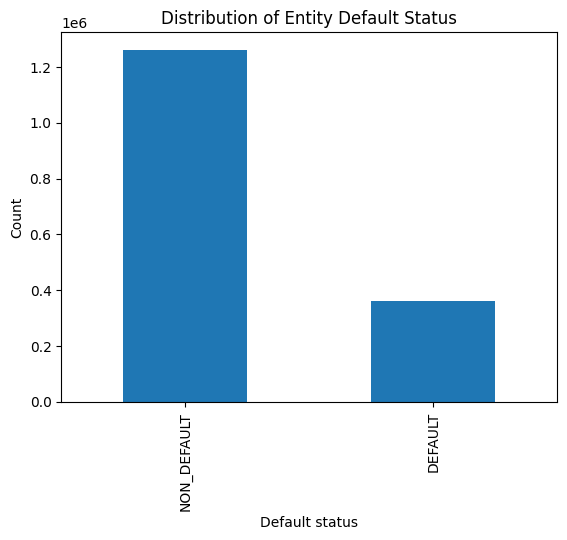

In [99]:
import matplotlib.pyplot as plt

df_eda["dflt_stts_entity"].value_counts(dropna=False).plot(kind="bar")
plt.title("Distribution of Entity Default Status")
plt.xlabel("Default status")
plt.ylabel("Count")
plt.show()

In [100]:
# Absolute counts
counts = df_eda["dflt_stts_entity"].value_counts(dropna=False)

# Percentages
percentages = df_eda["dflt_stts_entity"].value_counts(normalize=True, dropna=False) * 100

# Combine in one table
default_summary = pd.DataFrame({
    "count": counts,
    "percentage": percentages.round(2)
})

default_summary

,count,percentage
dflt_stts_entity,,
NON_DEFAULT,1261851,77.75
DEFAULT,361043,22.25


In [101]:
for status, row in default_summary.iterrows():
    print(f"{status}: {row['count']} observations ({row['percentage']}%)")

NON_DEFAULT: 1261851.0 observations (77.75%)
DEFAULT: 361043.0 observations (22.25%)


### Default status distribution

The distribution of the entity-level default status shows that the dataset is dominated by non-default observations, with approximately 70% classified as NON_DEFAULT and 30% as DEFAULT.

This indicates a moderate class imbalance, which is typical for credit risk data. The presence of a substantial number of default observations suggests that the dataset is suitable for risk analysis and potential modeling tasks.

In [102]:
df_eda["pd"].describe()

count    1.622894e+06
mean     2.207191e-01
std      3.885275e-01
min      2.000000e-03
25%      6.800000e-03
50%      1.350000e-02
75%      4.870000e-02
max      1.000000e+00
Name: pd, dtype: float64

Some conclusions:

the mean is very low -  0.0154

huge jump between 50% and 75 % from 0.0154 to 0.94

std shows a very large spread

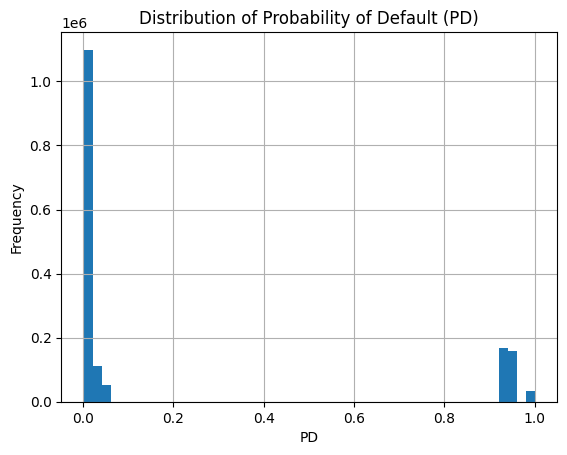

In [103]:
plt.figure()
df_eda["pd"].dropna().hist(bins=50)
plt.title("Distribution of Probability of Default (PD)")
plt.xlabel("PD")
plt.ylabel("Frequency")
plt.show()

- a large concentration of observations with very low PD values (close to 0)
- a smaller but significant group of observations with PD values close to 1

In [104]:
df_eda["otstndng_nmnl_amnt"].describe()

count    1.622894e+06
mean     4.830975e+05
std      9.604330e+05
min      0.000000e+00
25%      0.000000e+00
50%      8.000000e+00
75%      5.268842e+05
max      8.849244e+06
Name: otstndng_nmnl_amnt, dtype: float64

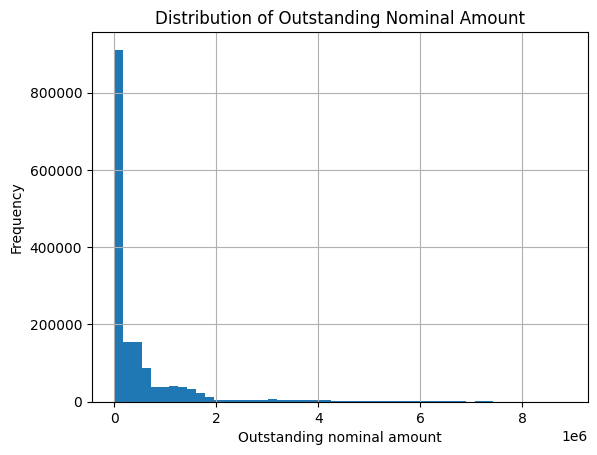

In [105]:
plt.figure()
df_eda["otstndng_nmnl_amnt"].dropna().hist(bins=50)
plt.title("Distribution of Outstanding Nominal Amount")
plt.xlabel("Outstanding nominal amount")
plt.ylabel("Frequency")
plt.show()

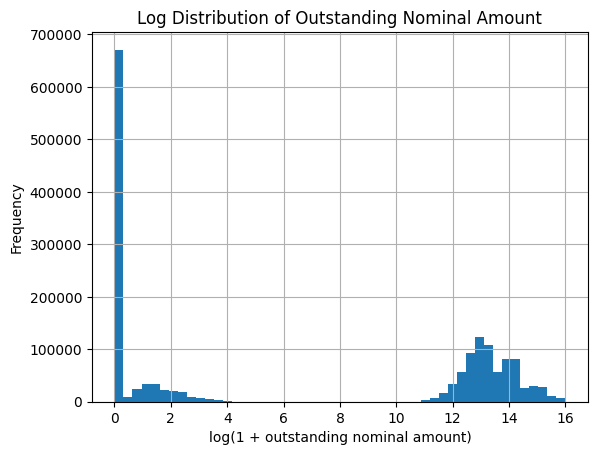

In [106]:
import numpy as np

plt.figure()
np.log1p(df_eda["otstndng_nmnl_amnt"].dropna()).hist(bins=50)
plt.title("Log Distribution of Outstanding Nominal Amount")
plt.xlabel("log(1 + outstanding nominal amount)")
plt.ylabel("Frequency")
plt.show()

### Distribution of outstanding nominal amount

The distribution of the outstanding nominal amount is highly right-skewed, with a large concentration of observations near zero and a long tail extending to very large values.

A significant proportion of observations have zero exposure, indicating inactive or fully repaid instruments.

The log-transformed distribution reveals a more structured pattern, with three distinct groups:
- a large mass of zero exposures
- a cluster of small exposures
- a separate cluster of large exposures

This segmentation reflects the typical structure of financial data, where a small number of large exposures coexist with many smaller ones.

The strong skewness suggests that log transformation is appropriate for further analysis and modeling.

### Log transformation of exposure variables

Exposure variables exhibit strong right skewness, with a large number of small values and a few very large observations.

To improve interpretability, a log transformation is applied. The transformation uses `log(1 + x)` to ensure that zero values are handled correctly.

In the current step, the transformation is applied only for visualisation purposes. In later stages, a transformed variable may be created for analytical or modeling use.

- a large concentration of observations with very low PD values (close to 0)
- a smaller but significant group of observations with PD values close to 1

In [107]:
# df_eda["total_exposure"].dropna().hist(bins=50)
# plt.title("Distribution of Total Exposure")
# plt.xlabel("Total exposure")
# plt.ylabel("Frequency")
# plt.show()

- a large concentration of observations with very low PD values (close to 0)
- a smaller but significant group of observations with PD values close to 1

## Feature engenering

In [108]:
df_debtor["total_exposure"] = (
    df_debtor["otstndng_nmnl_amnt"].fillna(0) +
    df_debtor["off_blnc_sht_amnt"].fillna(0)
)

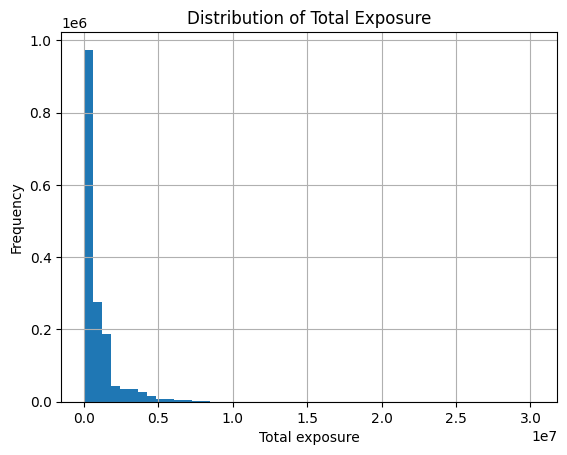

In [109]:
plt.figure()
df_debtor["total_exposure"].dropna().hist(bins=50)
plt.title("Distribution of Total Exposure")
plt.xlabel("Total exposure")
plt.ylabel("Frequency")
plt.show()

In [110]:
#utilization ratio
df_debtor["utilisation_ratio"] = (
    df_debtor["otstndng_nmnl_amnt"] /
    df_debtor["total_exposure"]
)

In [111]:
df_debtor["total_exposure"].describe()

count    1.622894e+06
mean     8.902384e+05
std      1.157518e+06
min      0.000000e+00
25%      2.429108e+05
50%      4.785165e+05
75%      1.126774e+06
max      3.028554e+07
Name: total_exposure, dtype: float64

In [112]:
#log transforfation to reduce skewness
df_debtor["log_total_exposure"] = np.log1p(df_eda["total_exposure"])

In [113]:
#utilization ratio
df_debtor["utilisation_ratio"] = (
    df_debtor["otstndng_nmnl_amnt"] /
    df_debtor["total_exposure"]
)

In [114]:
#remove problematic values (NaN, inf, zeros if needed)
temp = df_debtor.dropna(subset=["utilisation_ratio", "dflt_stts_entity"]).copy()

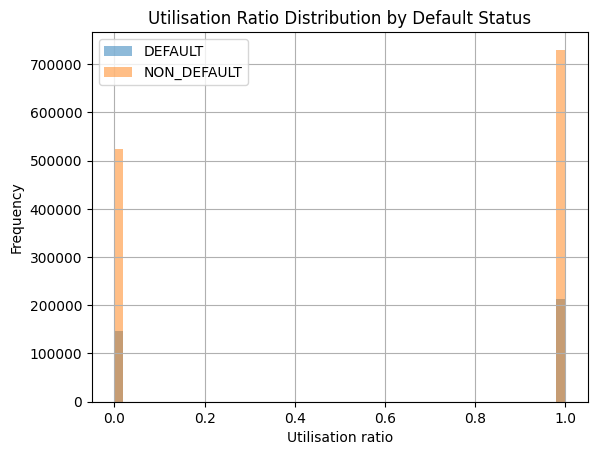

In [115]:
import matplotlib.pyplot as plt

plt.figure()

temp[temp["dflt_stts_entity"] == "DEFAULT"]["utilisation_ratio"].hist(
    bins=50, alpha=0.5, label="DEFAULT"
)

temp[temp["dflt_stts_entity"] == "NON_DEFAULT"]["utilisation_ratio"].hist(
    bins=50, alpha=0.5, label="NON_DEFAULT"
)

plt.title("Utilisation Ratio Distribution by Default Status")
plt.xlabel("Utilisation ratio")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [116]:
df_debtor["profit_ratio"] = (
   df_debtor["annl_trnvr_le"] / df_debtor["blnc_sht_ttl_le"]
).replace([np.inf, -np.inf], np.nan)

In [117]:
# 3. convert dates
df_debtor["dt_rfrnc"] = pd.to_datetime(df_debtor["dt_rfrnc"], errors="coerce")
df_debtor["dt_pst_d"] = pd.to_datetime(df_debtor["dt_pst_d"], errors="coerce")

# 4. days past due
df_debtor["days_past_due"] = (
    df_debtor["dt_rfrnc"] - df_debtor["dt_pst_d"]
).dt.days

# 5. max days past due per entity-instrument
df_debtor["max_days_past_due"] = df_debtor.groupby(
    ["entty_riad_id", "cntrct_id", "instrmnt_id", "obsrvd_agnt_id"]
)["days_past_due"].transform("max")

In [118]:
df_debtor["max_days_past_due"].isna().sum()

np.int64(1152844)

In [119]:
df_debtor["max_days_past_due"] = df_debtor["max_days_past_due"].fillna(0)

In [120]:
#create clean df for the prediction
predict_cols = [
    "dflt_stts_entity",   # target
    "cntry",
    "instttnl_sctr",
    "entrprs_sz_le",
    "typ_instrmnt",
    "blnc_sht_ttl_le",
    "annl_trnvr_le",
    "total_exposure",
    "log_total_exposure",
    "utilisation_ratio",
    'profit_ratio',
    'max_days_past_due'
]

df_predict = df_debtor[predict_cols].copy()

In [121]:
df_predict.head()

,dflt_stts_entity,cntry,instttnl_sctr,entrprs_sz_le,typ_instrmnt,blnc_sht_ttl_le,annl_trnvr_le,total_exposure,log_total_exposure,utilisation_ratio,profit_ratio,max_days_past_due
0,NON_DEFAULT,FR,S11,3,1004,10613348.31,500000.00,1233951.79,14.025733,1.000000,0.047110,0.0
3,NON_DEFAULT,IT,S11,3,1002,500000.00,500000.00,1623255.02,14.299945,0.000000,1.000000,0.0
6,NON_DEFAULT,FR,S11,4,1002,319656.50,441000.00,533725.46,13.187639,0.000000,1.379606,0.0
9,NON_DEFAULT,FR,S11,2,1002,2000000.00,2000000.00,2327685.82,14.660386,1.000000,1.000000,0.0
12,NON_DEFAULT,IT,S11,4,1002,1738984.03,894228.74,238765.01,12.383239,0.000005,0.514225,0.0


In [122]:
#utilisation ratio has issue, missing values NaN from the devision by 0
df_predict["utilisation_ratio"] = df_predict["utilisation_ratio"].fillna(0)

In [123]:
df_predict["utilisation_ratio"].value_counts()

utilisation_ratio
1.000000    943150
0.000000    670650
0.403247         3
0.919916         3
0.825542         3
             ...  
0.000004         1
0.000005         1
0.000005         1
0.449737         1
0.000006         1
Name: count, Length: 9006, dtype: int64

In [124]:
#convert the target to binary value
df_predict["default_flag"] = (
    df_predict["dflt_stts_entity"] == "DEFAULT"
).astype(int)

In [125]:
#drop the original column
df_predict = df_predict.drop(columns=["dflt_stts_entity"])

In [126]:
df_predict.info()
df_predict.head()

<class 'pandas.DataFrame'>
Index: 1622894 entries, 0 to 4848466
Data columns (total 12 columns):
 #   Column              Non-Null Count    Dtype  
---  ------              --------------    -----  
 0   cntry               1622894 non-null  str    
 1   instttnl_sctr       1622894 non-null  str    
 2   entrprs_sz_le       1622894 non-null  int64  
 3   typ_instrmnt        1622894 non-null  int64  
 4   blnc_sht_ttl_le     1622894 non-null  float64
 5   annl_trnvr_le       1622894 non-null  float64
 6   total_exposure      1622894 non-null  float64
 7   log_total_exposure  1622894 non-null  float64
 8   utilisation_ratio   1622894 non-null  float64
 9   profit_ratio        1622894 non-null  float64
 10  max_days_past_due   1622894 non-null  float64
 11  default_flag        1622894 non-null  int64  
dtypes: float64(7), int64(3), str(2)
memory usage: 161.0 MB


,cntry,instttnl_sctr,entrprs_sz_le,typ_instrmnt,blnc_sht_ttl_le,annl_trnvr_le,total_exposure,log_total_exposure,utilisation_ratio,profit_ratio,max_days_past_due,default_flag
0,FR,S11,3,1004,10613348.31,500000.00,1233951.79,14.025733,1.000000,0.047110,0.0,0
3,IT,S11,3,1002,500000.00,500000.00,1623255.02,14.299945,0.000000,1.000000,0.0,0
6,FR,S11,4,1002,319656.50,441000.00,533725.46,13.187639,0.000000,1.379606,0.0,0
9,FR,S11,2,1002,2000000.00,2000000.00,2327685.82,14.660386,1.000000,1.000000,0.0,0
12,IT,S11,4,1002,1738984.03,894228.74,238765.01,12.383239,0.000005,0.514225,0.0,0


In [127]:
df_predict.dtypes

cntry                     str
instttnl_sctr             str
entrprs_sz_le           int64
typ_instrmnt            int64
blnc_sht_ttl_le       float64
annl_trnvr_le         float64
total_exposure        float64
log_total_exposure    float64
utilisation_ratio     float64
profit_ratio          float64
max_days_past_due     float64
default_flag            int64
dtype: object

In [128]:
df_predict["cntry"].value_counts(normalize=True).head(10)

cntry
FR    0.343529
IT    0.257715
BE    0.151583
PT    0.088906
ES    0.064893
DE    0.062673
FI    0.028230
LU    0.000481
NL    0.000479
SM    0.000230
Name: proportion, dtype: float64

In [129]:
top_countries = ["FR", "IT", "BE"]

df_predict["cntry_grouped"] = df_predict["cntry"].apply(
    lambda x: x if x in top_countries else "Other"
)

In [130]:
df_predict["cntry_grouped"].isna().sum()

np.int64(0)

In [131]:
df_predict

,cntry,instttnl_sctr,entrprs_sz_le,typ_instrmnt,blnc_sht_ttl_le,annl_trnvr_le,total_exposure,log_total_exposure,utilisation_ratio,profit_ratio,max_days_past_due,default_flag,cntry_grouped
0,FR,S11,3,1004,10613348.31,500000.00,1233951.79,14.025733,1.000000,0.047110,0.0,0,FR
3,IT,S11,3,1002,500000.00,500000.00,1623255.02,14.299945,0.000000,1.000000,0.0,0,IT
6,FR,S11,4,1002,319656.50,441000.00,533725.46,13.187639,0.000000,1.379606,0.0,0,FR
9,FR,S11,2,1002,2000000.00,2000000.00,2327685.82,14.660386,1.000000,1.000000,0.0,0,FR
12,IT,S11,4,1002,1738984.03,894228.74,238765.01,12.383239,0.000005,0.514225,0.0,0,IT
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848454,FR,S11,4,1002,9844646.35,108291.12,3.19,1.432701,1.000000,0.011000,0.0,0,FR
4848457,BE,S11,3,1002,656309.78,656309.78,9.05,2.307573,1.000000,1.000000,0.0,0,BE
4848460,PT,S11,4,1002,715042.26,1173782.09,574889.05,13.261934,0.000000,1.641556,0.0,1,Other
4848463,ES,S11,3,1002,3276298.34,7702577.34,10.17,2.413232,1.000000,2.351000,0.0,0,Other


In [132]:
df_predict = df_predict.drop(columns=["cntry"])

In [133]:
categorical_cols = ["cntry_grouped", "instttnl_sctr"]

In [134]:
#df_predict.to_csv('df_predict.csv')

In [135]:
df_predict_encoded = pd.get_dummies(
    df_predict,
    columns=categorical_cols,
    drop_first=True
)

In [136]:
df_predict_encoded.info()

<class 'pandas.DataFrame'>
Index: 1622894 entries, 0 to 4848466
Data columns (total 20 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   entrprs_sz_le        1622894 non-null  int64  
 1   typ_instrmnt         1622894 non-null  int64  
 2   blnc_sht_ttl_le      1622894 non-null  float64
 3   annl_trnvr_le        1622894 non-null  float64
 4   total_exposure       1622894 non-null  float64
 5   log_total_exposure   1622894 non-null  float64
 6   utilisation_ratio    1622894 non-null  float64
 7   profit_ratio         1622894 non-null  float64
 8   max_days_past_due    1622894 non-null  float64
 9   default_flag         1622894 non-null  int64  
 10  cntry_grouped_FR     1622894 non-null  bool   
 11  cntry_grouped_IT     1622894 non-null  bool   
 12  cntry_grouped_Other  1622894 non-null  bool   
 13  instttnl_sctr_S11    1622894 non-null  bool   
 14  instttnl_sctr_S1311  1622894 non-null  bool   
 15  instttnl_sctr_

In [137]:
df_predict.isna().sum()

instttnl_sctr         0
entrprs_sz_le         0
typ_instrmnt          0
blnc_sht_ttl_le       0
annl_trnvr_le         0
total_exposure        0
log_total_exposure    0
utilisation_ratio     0
profit_ratio          0
max_days_past_due     0
default_flag          0
cntry_grouped         0
dtype: int64

In [138]:
X = df_predict_encoded.drop(columns=["default_flag"])
y = df_predict_encoded["default_flag"]

In [139]:
X.shape



(1622894, 19)

In [140]:
y.shape

(1622894,)

In [141]:
X

,entrprs_sz_le,typ_instrmnt,blnc_sht_ttl_le,annl_trnvr_le,total_exposure,log_total_exposure,utilisation_ratio,profit_ratio,max_days_past_due,cntry_grouped_FR,cntry_grouped_IT,cntry_grouped_Other,instttnl_sctr_S11,instttnl_sctr_S1311,instttnl_sctr_S1312,instttnl_sctr_S1313,instttnl_sctr_S1314,instttnl_sctr_S14,instttnl_sctr_S15
0,3,1004,10613348.31,500000.00,1233951.79,14.025733,1.000000,0.047110,0.0,True,False,False,True,False,False,False,False,False,False
3,3,1002,500000.00,500000.00,1623255.02,14.299945,0.000000,1.000000,0.0,False,True,False,True,False,False,False,False,False,False
6,4,1002,319656.50,441000.00,533725.46,13.187639,0.000000,1.379606,0.0,True,False,False,True,False,False,False,False,False,False
9,2,1002,2000000.00,2000000.00,2327685.82,14.660386,1.000000,1.000000,0.0,True,False,False,True,False,False,False,False,False,False
12,4,1002,1738984.03,894228.74,238765.01,12.383239,0.000005,0.514225,0.0,False,True,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4848454,4,1002,9844646.35,108291.12,3.19,1.432701,1.000000,0.011000,0.0,True,False,False,True,False,False,False,False,False,False
4848457,3,1002,656309.78,656309.78,9.05,2.307573,1.000000,1.000000,0.0,False,False,False,True,False,False,False,False,False,False
4848460,4,1002,715042.26,1173782.09,574889.05,13.261934,0.000000,1.641556,0.0,False,False,True,True,False,False,False,False,False,False
4848463,3,1002,3276298.34,7702577.34,10.17,2.413232,1.000000,2.351000,0.0,False,False,True,True,False,False,False,False,False,False


In [142]:
from sklearn.model_selection import train_test_split

X = df_predict_encoded.drop(columns=["default_flag"])
y = df_predict_encoded["default_flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y   
)

In [143]:
X_train.isna().sum().sort_values(ascending=False)

entrprs_sz_le          0
typ_instrmnt           0
blnc_sht_ttl_le        0
annl_trnvr_le          0
total_exposure         0
log_total_exposure     0
utilisation_ratio      0
profit_ratio           0
max_days_past_due      0
cntry_grouped_FR       0
cntry_grouped_IT       0
cntry_grouped_Other    0
instttnl_sctr_S11      0
instttnl_sctr_S1311    0
instttnl_sctr_S1312    0
instttnl_sctr_S1313    0
instttnl_sctr_S1314    0
instttnl_sctr_S14      0
instttnl_sctr_S15      0
dtype: int64

In [144]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [145]:
from sklearn.metrics import accuracy_score

# predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# accuracy
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print("Train accuracy:", round(train_acc, 4))
print("Test accuracy:", round(test_acc, 4))

Train accuracy: 0.7804
Test accuracy: 0.7805


In [146]:
from sklearn.metrics import classification_report

print("Classification report on test set:\n")
print(classification_report(y_test, y_test_pred))

Classification report on test set:

              precision    recall  f1-score   support

           0       0.78      0.99      0.88    378556
           1       0.58      0.05      0.09    108313

    accuracy                           0.78    486869
   macro avg       0.68      0.52      0.48    486869
weighted avg       0.74      0.78      0.70    486869



In [147]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)
print(cm)

[[374914   3642]
 [103221   5092]]


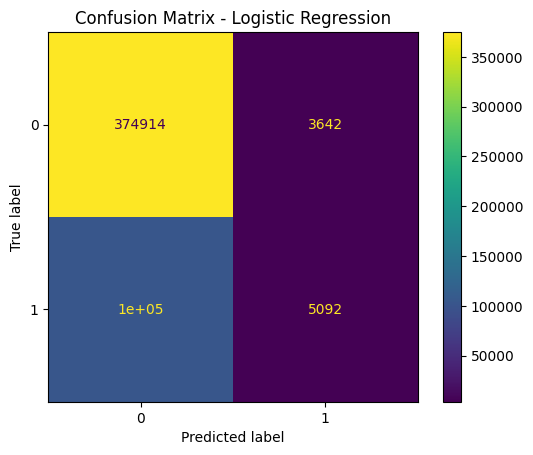

In [148]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

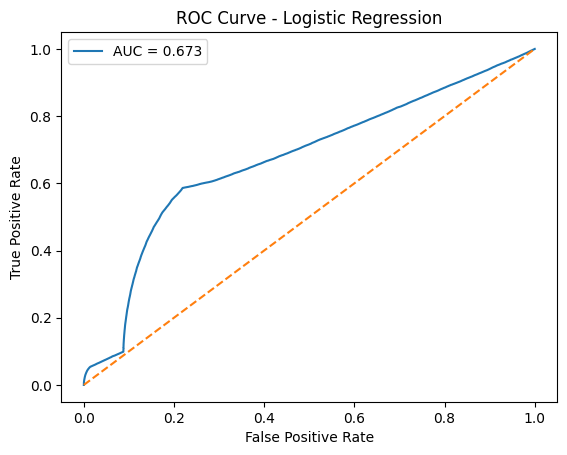

ROC AUC: 0.6727


In [149]:
from sklearn.metrics import roc_curve, roc_auc_score

y_test_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
auc_score = roc_auc_score(y_test, y_test_proba)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc_score:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

print("ROC AUC:", round(auc_score, 4))

In [150]:
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0]
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False)

coef_df.head(20)

,feature,coefficient,abs_coefficient
1,typ_instrmnt,-1.298832e-03,1.298832e-03
8,max_days_past_due,3.772172e-04,3.772172e-04
5,log_total_exposure,-1.333956e-05,1.333956e-05
0,entrprs_sz_le,-5.305106e-06,5.305106e-06
12,instttnl_sctr_S11,-1.355687e-06,1.355687e-06
7,profit_ratio,-1.106133e-06,1.106133e-06
6,utilisation_ratio,-8.210479e-07,8.210479e-07
9,cntry_grouped_FR,-4.835781e-07,4.835781e-07
10,cntry_grouped_IT,-3.663971e-07,3.663971e-07
11,cntry_grouped_Other,-3.341837e-07,3.341837e-07


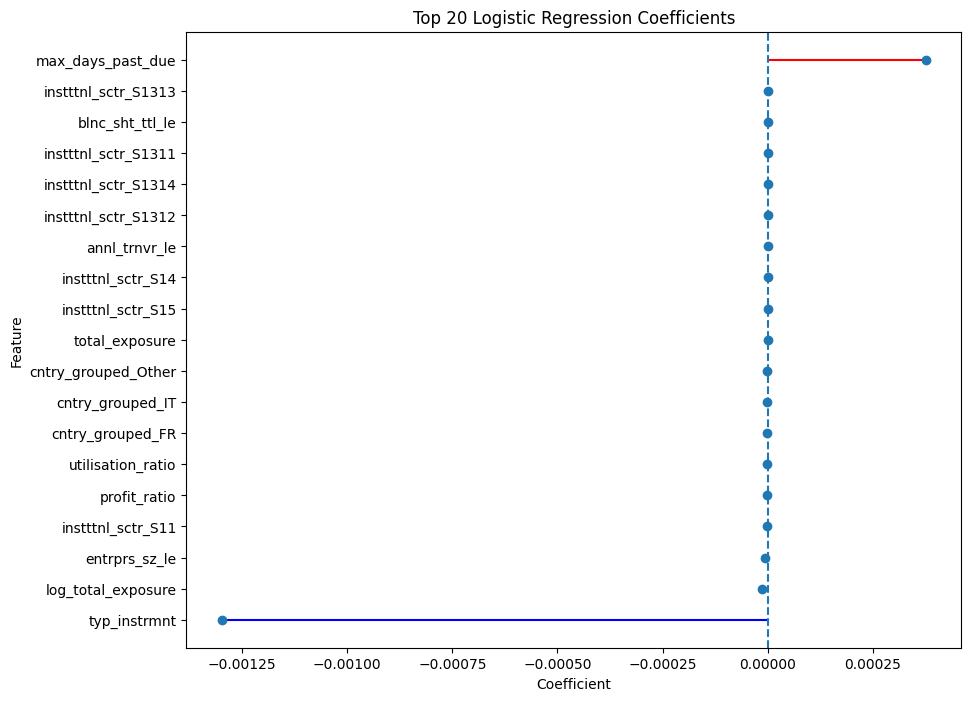

In [151]:
top_n = 20
coef_plot = coef_df.head(top_n).sort_values("coefficient")

plt.figure(figsize=(10, 8))
colors = ["red" if x > 0 else "blue" for x in coef_plot["coefficient"]]

plt.hlines(
    y=coef_plot["feature"],
    xmin=0,
    xmax=coef_plot["coefficient"],
    color=colors
)
plt.plot(coef_plot["coefficient"], coef_plot["feature"], "o")
plt.axvline(0, linestyle="--")
plt.title(f"Top {top_n} Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

In [152]:
from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [153]:
print(X_train_imputed.isna().sum().sum())
print(X_test_imputed.isna().sum().sum())

0
0


In [154]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train_imputed, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [155]:
y_pred = model.predict(X_test_imputed)
y_pred_proba = model.predict_proba(X_test_imputed)[:, 1]

In [156]:


print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.31709145581254916
              precision    recall  f1-score   support

           0       0.86      0.14      0.25    378556
           1       0.24      0.92      0.37    108313

    accuracy                           0.32    486869
   macro avg       0.55      0.53      0.31    486869
weighted avg       0.72      0.32      0.28    486869



In [157]:

auc = roc_auc_score(y_test, y_pred_proba)
print("ROC AUC:", round(auc, 4))

ROC AUC: 0.5287


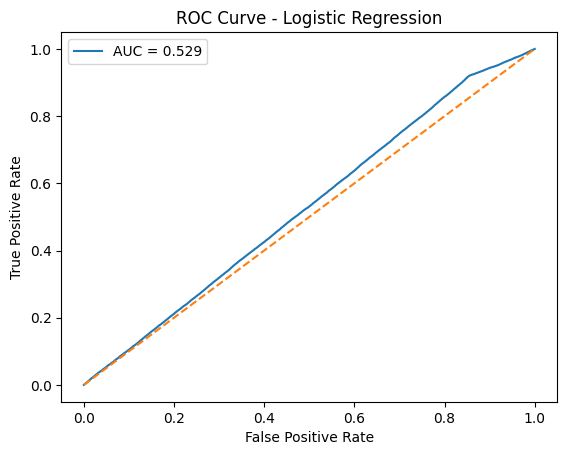

In [158]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

In [159]:
y_train_proba = model.predict_proba(X_train_imputed)[:, 1]

train_auc = roc_auc_score(y_train, y_train_proba)
test_auc = roc_auc_score(y_test, y_pred_proba)

print("Train AUC:", round(train_auc, 4))
print("Test AUC:", round(test_auc, 4))
print("AUC gap:", round(train_auc - test_auc, 4))

Train AUC: 0.5282
Test AUC: 0.5287
AUC gap: -0.0004


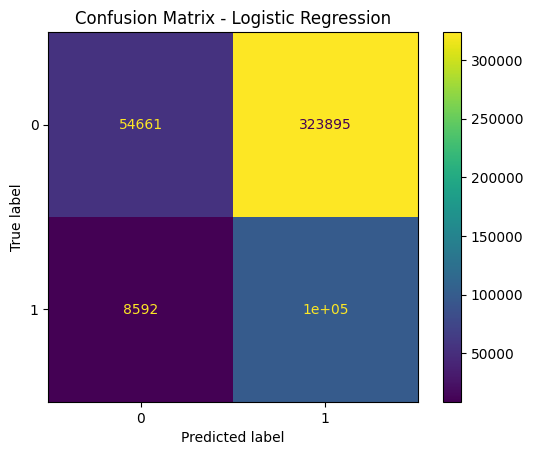

In [160]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [161]:
coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0]
}).sort_values(by="coefficient", key=abs, ascending=False)

coef_df.head(10)

,feature,coefficient
4,total_exposure,2.875824e-08
3,annl_trnvr_le,-1.125578e-09
8,max_days_past_due,2.389216e-10
1,typ_instrmnt,-1.306680e-11
2,blnc_sht_ttl_le,7.827422e-12
5,log_total_exposure,4.661559e-13
0,entrprs_sz_le,-1.544763e-14
7,profit_ratio,-1.119416e-14
6,utilisation_ratio,5.186044e-15
12,instttnl_sctr_S11,-4.684867e-15


In [162]:
coef_df = coef_df.copy()
coef_df["abs_coef"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=False)

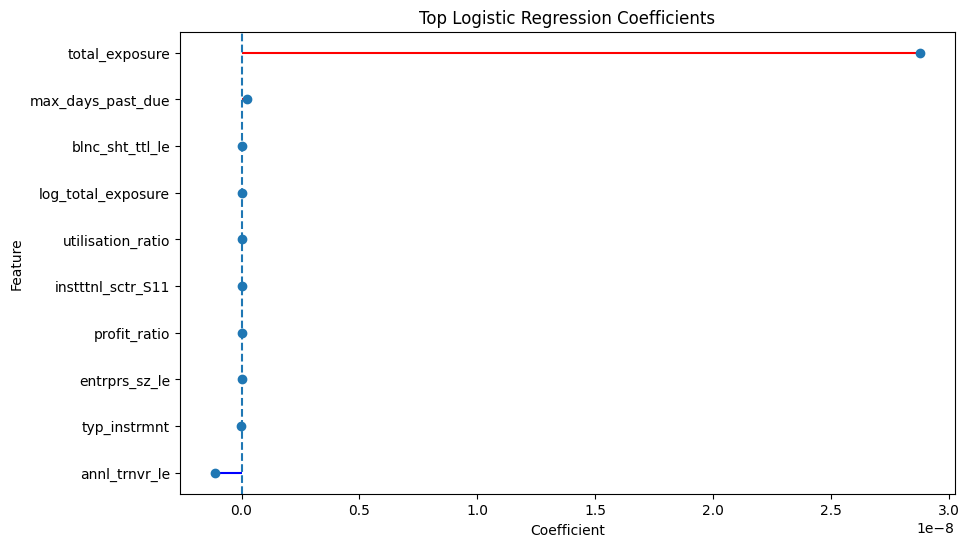

In [163]:
top_n = 10
coef_plot = coef_df.head(top_n).sort_values("coefficient")

plt.figure(figsize=(10, 6))

colors = ["red" if x > 0 else "blue" for x in coef_plot["coefficient"]]

plt.hlines(
    y=coef_plot["feature"],
    xmin=0,
    xmax=coef_plot["coefficient"],
    color=colors
)

plt.plot(coef_plot["coefficient"], coef_plot["feature"], "o")
plt.axvline(0, linestyle="--")

plt.title("Top Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

In [164]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_imputed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [165]:
y_pred_rf = rf_model.predict(X_test_imputed)
y_pred_proba_rf = rf_model.predict_proba(X_test_imputed)[:, 1]

In [166]:
print("RF Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("\nRandom Forest classification report:\n")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred_rf))
print("\nRF ROC AUC:", round(roc_auc_score(y_test, y_pred_proba_rf), 4))

RF Accuracy: 0.8823

Random Forest classification report:

              precision    recall  f1-score   support

           0       0.91      0.95      0.93    378556
           1       0.78      0.66      0.71    108313

    accuracy                           0.88    486869
   macro avg       0.84      0.80      0.82    486869
weighted avg       0.88      0.88      0.88    486869


Confusion matrix:
 [[357869  20687]
 [ 36603  71710]]

RF ROC AUC: 0.905


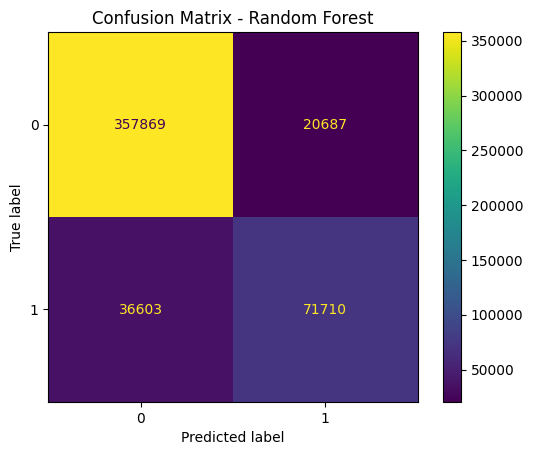

In [167]:
cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix - Random Forest")
plt.show()

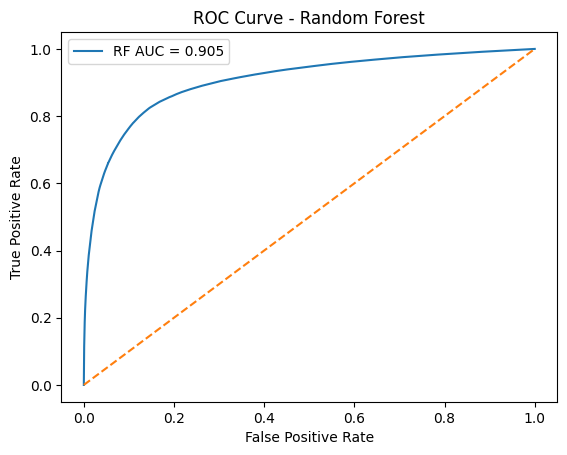

In [168]:
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
auc_rf = roc_auc_score(y_test, y_pred_proba_rf)

plt.figure()
plt.plot(fpr_rf, tpr_rf, label=f"RF AUC = {auc_rf:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

In [169]:
importance_df = pd.DataFrame({
    "feature": X_train_imputed.columns,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

importance_df.head(10)

,feature,importance
8,max_days_past_due,0.219374
4,total_exposure,0.167370
2,blnc_sht_ttl_le,0.167090
5,log_total_exposure,0.166812
3,annl_trnvr_le,0.163687
7,profit_ratio,0.061511
1,typ_instrmnt,0.018164
9,cntry_grouped_FR,0.008110
10,cntry_grouped_IT,0.007802
11,cntry_grouped_Other,0.007373


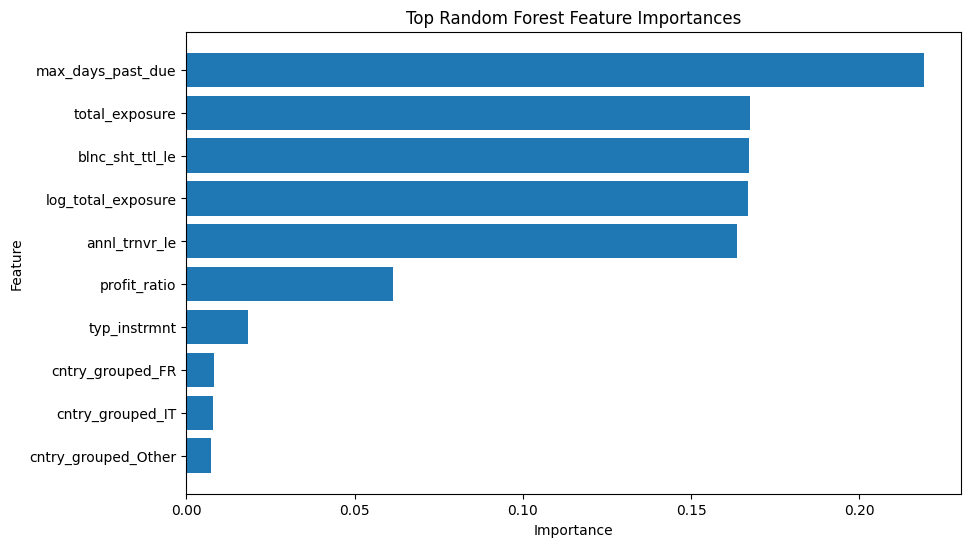

In [170]:
top_n = 10
imp_plot = importance_df.head(top_n).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(imp_plot["feature"], imp_plot["importance"])
plt.title("Top Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

## Model Comparison: Logistic Regression vs Random Forest

Two modeling approaches were applied to predict default: Logistic Regression and Random Forest.

### Logistic Regression

Logistic Regression was used as a baseline linear classifier.  
Its results showed limited discriminatory power:

- ROC AUC close to 0.51
- poor overall separation between defaulted and non-defaulted observations
- very weak coefficient interpretability in the raw-scale setup
- strong sensitivity to class imbalance and threshold choice

Although the balanced version improved recall for defaults, it did so at the expense of accuracy and precision. Overall, the linear model did not capture the structure of the data well.

### Random Forest

Random Forest performed substantially better than Logistic Regression.

Its advantages in this project were:

- better ability to capture non-linear relationships
- improved handling of interactions between variables
- stronger predictive performance
- more meaningful ranking of feature importance

This suggests that the relationship between the predictors and default status is not purely linear and is better represented by a non-linear model.

### Main conclusion

The comparison indicates that Random Forest is more appropriate for this dataset than Logistic Regression.

The linear model served as a useful benchmark, but the Random Forest was able to extract more predictive signal from the available variables. This result is consistent with the structure of the data, which includes non-linear patterns, grouped categorical effects.

